# INTERACTING QUEUES: A REPLICA MEAN-FIELD APPROACH IN THE GEOMETRIC SETTING

In [21]:
import matplotlib.pyplot as plt
import numpy as np 
from scipy.optimize import fsolve
import random
from scipy.stats import wasserstein_distance
from scipy.optimize import fixed_point
from tqdm import tqdm  # Barre texte explicite, sans auto ni widgets utilisateur
from scipy.special import gammaln
import math

In [22]:
torus_size=100


In [23]:
def torus_distance(x, y, torus_size):
    """
    Compute the Euclidean periodic distance between two points on a torus.

    Parameters
    ----------
    x, y : array-like or float
        Coordinates of the two points.
        For a one-dimensional torus, x and y can be scalars.
    torus_size : array-like or float
        Size of the torus in each dimension.
        A scalar means that all dimensions have the same size.

    Returns
    -------
    float
        Periodic Euclidean distance between x and y.
    """
    x = np.atleast_1d(np.asarray(x, dtype=float))
    y = np.atleast_1d(np.asarray(y, dtype=float))
    torus_size = np.asarray(torus_size, dtype=float)

    if np.any(torus_size <= 0):
        raise ValueError("The torus size must be strictly positive.")

    # Coordinate-wise direct distance
    delta = np.abs(x - y)

    # Coordinate-wise periodic distance
    periodic_delta = np.minimum(delta, torus_size - delta)

    # Euclidean distance on the torus
    return np.linalg.norm(periodic_delta)

In [ ]:
# Create the geometry 

def select_uniform_points(N, seed=42):
    random.seed(seed) 
    points = [random.uniform(0, N-1) for _ in range(N)]  # Select the point uniformly, here we choosed N for the size for dimension constraint but one could take T
    return sorted(points)  # Return the ordered points

def plot_points_reels(liste): # plot the configuration 
    x = liste              
    y = [0] * len(liste)  

    plt.figure(figsize=(8, 2))
    plt.scatter(x, y, c='red', s=10)

    plt.yticks([])                      
    plt.xlabel("Axe des réels")
    plt.title("Points sur l'axe des réels")
    plt.axhline(0, color='black', linewidth=0.5)  
    plt.grid(True, axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
#Type of omni directional pathloss used

def OPL(A,C,r_0,i):
    if i==1:
        return lambda r: 1/((A*np.maximum(r,r_0))**C)
    elif i==2:
        return lambda r: 1/((1+A*r)**C)
    elif i==3:
        return lambda r: A*np.exp(-C*r)


# Maximal interference felt when using f as atenuation function for each user on the torus.

def calcule_mu_star(psi,f,g):
    res=[]
    N=len(psi)
    for i in range(N):
        interference=0
        for j in range(len(psi)):
            distance=torus_distance(psi[i],psi[j],torus_size)
            if distance > 0:
                interference+=f(distance)
        res.append(g(interference))
    return res



# Type of departure rate function of the interference 

def Shanon_rate(B,W,p):
    return lambda x: B*np.log2(1+p/(W+x)) #true one

## True System Simulation

In [26]:
# Simulate the Dynamic of the True system 

# Compute the departure rate of queue i based on the workloads of others
def calculate_departure_rate(psi,workloads, i,f,g):
    N=len(workloads)
    interference=0
    for j in range(N):
        if workloads[j] > 0 and j != i: # if the neighbour j is buisy it affects i 
            distance =torus_distance(psi[i],psi[j],torus_size)
            interference+=f(distance)
    return g(interference)

# Compute Workloads and Delay for the system
def simulate_dynamic_queues(psi, lambda_, T_max,f,g):
    N=len(psi)
    t = 0
    workloads = [0] * N # list that contain the workloads  of each queue
    arrival_times_list = [[] for _ in range(N)] # list that contain the list of arrival time of each job in each queue 
    delays_list = [[] for _ in range(N)] # list that contain the list of delays  of each job in each queue
    times = [0]  # keep track of any time where the system changes
    all_workloads = [[0] for _ in range(N)] # keep in memory the state of workloads at each time the system changes
    while t < T_max:
        arrival_times = [np.random.exponential(1 / lambda_) for _ in range(N)] # Generate potential arrival time for each queue 
        departure_rates = [calculate_departure_rate(psi,workloads, i,f,g) for i in range(N)] 
        departure_times = [
            np.random.exponential(1 / rate) if rate > 0 and workloads[i] > 0 else float('inf')
            for i, rate in enumerate(departure_rates)
        ] # Generate potential departure time for each queue based on the wrokloads, workloads[i] > 0 check whether the queue is empty so that we can really pull out a job
        next_event_time = min(min(arrival_times), min(departure_times))# next event is the minimum between all those times 
        t += next_event_time
        if min(arrival_times) <= min(departure_times):# if it's an arrival that won the race
            queue_index = arrival_times.index(min(arrival_times)) # get the index of the queue who won
            workloads[queue_index] += 1 # add a job to the queue that won 
            arrival_times_list[queue_index].append(t)# we add the time at  which th job arrived in the queue that won 
        else:# if its a departure that won
            queue_index = departure_times.index(min(departure_times))# get the index 
            workloads[queue_index] -= 1 # pull of a job
            if arrival_times_list[queue_index]: # if the queue that won has jobs waiting 
                arrival_time = arrival_times_list[queue_index].pop(0) # we pop the first element of the waitng list( because it is the on being treated)
                delays_list[queue_index].append(t - arrival_time) # compute the time it tooked to be treated
        times.append(t) 
        for i in range(N):
            all_workloads[i].append(workloads[i])
    return times, all_workloads, delays_list

In [27]:
#Plot the workloads with respect to time 
def plot_workloads1(times, all_workloads, T_max, T):
    plt.figure(figsize=(12, 8))
    stationnary_times = [time for time in times if time >= T_max - T] # look at the stationnary times
    start_index = len(times) - len(stationnary_times)# start at the index for which it is stationarry time (times is a incrasing list)
    for i,workloads in enumerate(all_workloads):
        stationnary_workloads = workloads[start_index:]
        plt.step(stationnary_times , stationnary_workloads, label=f"Queue {i+1}")#use step so that it interpolates constantly between times
    plt.xlabel("Time")
    plt.ylabel("Workload")
    plt.title(f"Workload Dynamic Sationnary regime True System")
    plt.legend()
    plt.grid()
    plt.show()

# Plot the disribution of Delays in the stationnary regime 
def plot_delays1(all_delays,s):
    plt.figure(figsize=(12, 6))
    for i, delays in enumerate(all_delays):
        start_index = int(len(delays)*s) # We assume that stationnary regime is set for the last 1-s part of the jobs in the simulation
        stationnary_delays=delays[start_index:]
        plt.hist(stationnary_delays, bins=30, alpha=0.6, label=f"Queue {i+1}", density=True)
    plt.xlabel("Delay")
    plt.ylabel("Density")
    plt.title("Distribution of Delays in the Stationnary regime True System")
    plt.legend()
    plt.grid()
    plt.show()

# Plot the distribution of the Workloads in the stationnary regime
def plot_workload_distribution1(times,all_workloads,T_max,T):
    plt.figure(figsize=(12, 6))
    stationnary_times = [time for time in times if time >= T_max - T]
    start_index = len(times) - len(stationnary_times)
    for i, workloads in enumerate(all_workloads):
        stationnary_workloads = workloads[start_index:]# conserve only stationnary samples
        plt.hist(stationnary_workloads, bins=30, alpha=0.6, label=f"Queue {i+1}", density=True)
    plt.xlabel("Workload")
    plt.ylabel("Density")
    plt.yscale("log")
    plt.title("Workload distribution for each queue True System")
    plt.legend()
    plt.grid()
    plt.show()

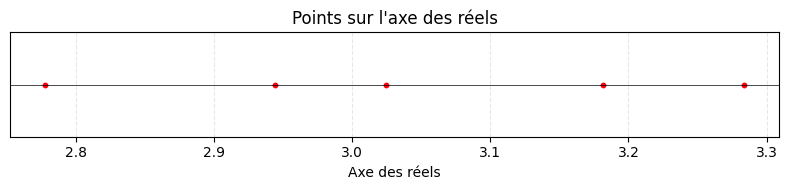

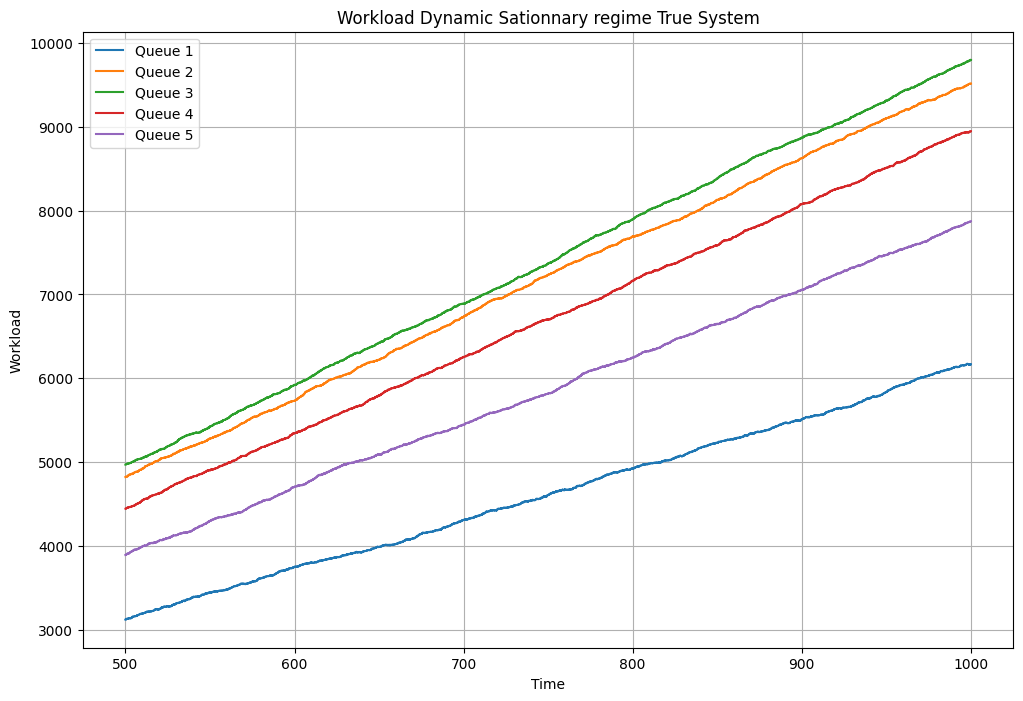

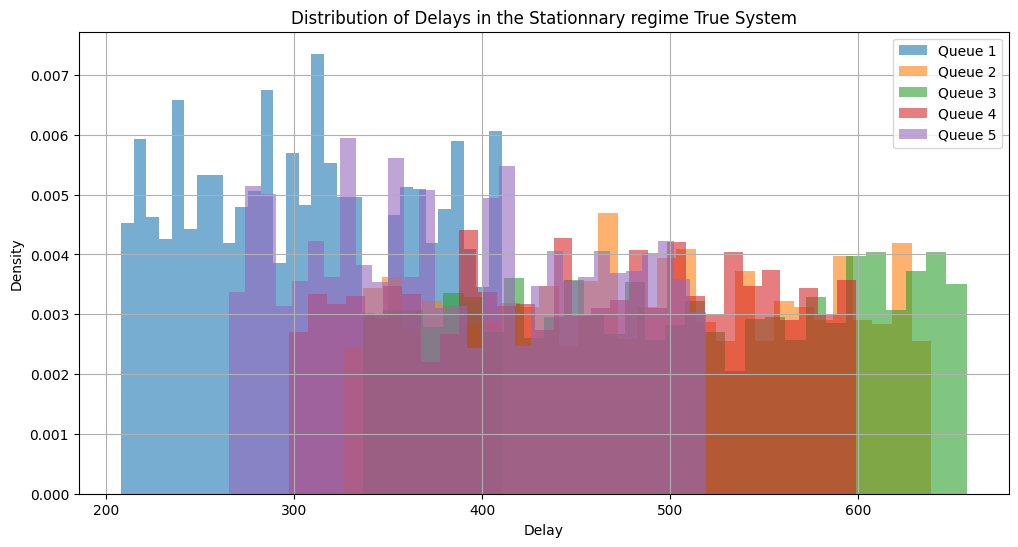

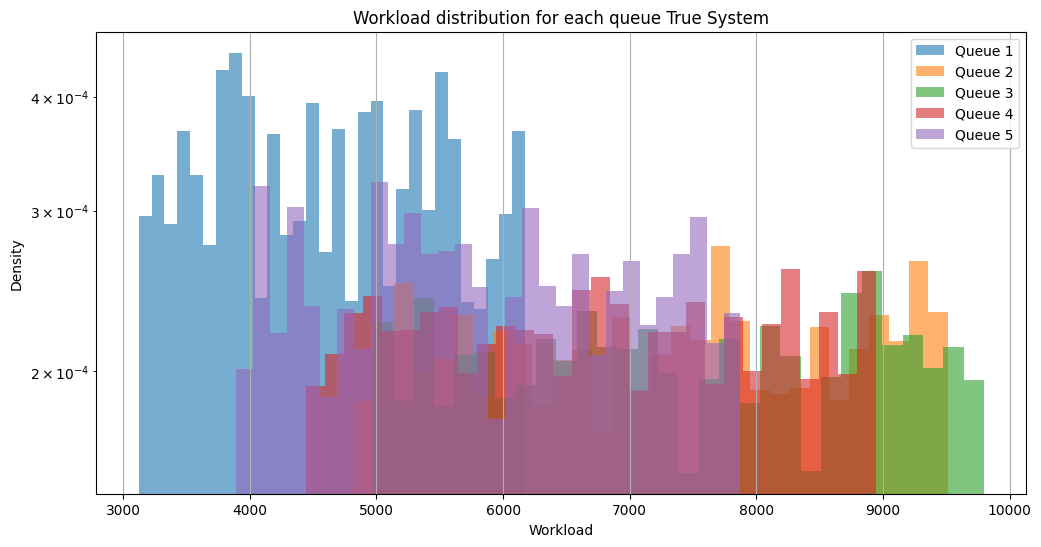

In [28]:
#Test

psi = select_uniform_points(5,None)
plot_points_reels(psi)
f,g=OPL(1,1,0,1),Shanon_rate(100,1,1)
T_max=10**3
T=5*10**2

times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi, 15, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)

plot_delays1(all_delays1,0.5)

plot_workload_distribution1(times1,all_workloads1,T_max,T)

##  Simulate Mean-Field 1

In [29]:
# Vectorized search for the fixed point 

def torus_distance_matrix(positions, torus_size):
    """
    Compute the matrix of pairwise periodic distances on a torus.

    Parameters
    ----------
    positions : array-like, shape (N,) or (N, d)
        Positions of the N points.
    torus_size : float or array-like of shape (d,)
        Size of the torus in each dimension.

    Returns
    -------
    distances : ndarray, shape (N, N)
        Matrix such that distances[i, j] is the periodic distance
        between points i and j.
    """
    positions = np.asarray(positions, dtype=float)

    # Convert one-dimensional positions to shape (N, 1)
    if positions.ndim == 1:
        positions = positions[:, None]

    torus_size = np.asarray(torus_size, dtype=float)

    if torus_size.ndim == 0:
        torus_size = np.full(positions.shape[1], torus_size)

    if len(torus_size) != positions.shape[1]:
        raise ValueError(
            "torus_size must have one value per spatial dimension."
        )

    if np.any(torus_size <= 0):
        raise ValueError("All torus sizes must be strictly positive.")

    # Reduce positions modulo the torus size
    positions = np.mod(positions, torus_size)

    # Pairwise coordinate differences, shape (N, N, d)
    delta = np.abs(
        positions[:, None, :] - positions[None, :, :]
    )

    # Apply periodic boundary conditions
    periodic_delta = np.minimum(delta, torus_size - delta)

    # Euclidean norm over the spatial dimensions
    distances = np.linalg.norm(periodic_delta, axis=2)

    return distances


def interaction_matrix(positions, torus_size, path_loss):
    """
    Build the interaction matrix.

    The coefficient A[i, j] is path_loss(distance(i, j))
    for i != j. The diagonal is set to zero to remove
    self-interference.

    Parameters
    ----------
    positions : array-like, shape (N,) or (N, d)
        Positions of the points.
    torus_size : float or array-like
        Size of the torus.
    path_loss : callable
        Interaction function applied to distances.

    Returns
    -------
    A : ndarray, shape (N, N)
        Interaction matrix.
    """
    distances = torus_distance_matrix(positions, torus_size)
    N = distances.shape[0]

    A = np.zeros((N, N), dtype=float)

    # Apply path_loss only outside the diagonal.
    # This avoids evaluating singular functions such as 1 / distance**alpha
    # at distance zero.
    mask = ~np.eye(N, dtype=bool)
    A[mask] = path_loss(distances[mask])

    if np.any(A < 0):
        raise ValueError("The path-loss function must be non-negative.")

    return A


def find_fixed_point(
    lambda_,
    positions,
    torus_size,
    path_loss,
    g,
    x0=None,
    tolerance=1e-10,
    max_iterations=10000,
    relaxation=1.0
):
    """
    Find a fixed point of

        F_i(x) = min(lambda / g((A x)_i), 1).

    Parameters
    ----------
    lambda_ : float
        Model parameter lambda.
    positions : array-like, shape (N,) or (N, d)
        Positions of the points.
    torus_size : float or array-like
        Size of the torus.
    path_loss : callable
        Non-negative interaction function.
    g : callable
        Positive denominator function.
        It should accept a NumPy array.
    x0 : array-like, optional
        Initial condition. The default is the zero vector.
    tolerance : float
        Stopping tolerance for the infinity norm.
    max_iterations : int
        Maximum number of fixed-point iterations.
    relaxation : float
        Relaxation parameter in (0, 1].
        Use a value smaller than 1 if direct iteration oscillates.

    Returns
    -------
    x : ndarray
        Approximate fixed point.
    converged : bool
        True if the stopping criterion was satisfied.
    iterations : int
        Number of iterations performed.
    """
    if lambda_ < 0:
        raise ValueError("lambda_ must be non-negative.")

    if not 0 < relaxation <= 1:
        raise ValueError("relaxation must belong to (0, 1].")

    # Build the interaction matrix only once
    A = interaction_matrix(
        positions=positions,
        torus_size=torus_size,
        path_loss=path_loss
    )

    N = A.shape[0]

    # Starting from zero gives the smallest fixed point
    # when the fixed-point map is monotone.
    if x0 is None:
        x = np.zeros(N)
    else:
        x = np.clip(np.asarray(x0, dtype=float), 0.0, 1.0)

        if x.shape != (N,):
            raise ValueError(f"x0 must have shape ({N},).")

    # Pas de barre ici : ce solveur est appelé de nombreuses fois par les expériences.
    # La granularité est une itération interne sans durée totale fiable; la barre
    # principale (cellule 23) donne une progression globale sans multiplier les sorties.
    for iteration in range(1, max_iterations + 1):

        # Compute all interferences using one matrix-vector product
        interference = A @ x

        denominator = np.asarray(g(interference), dtype=float)

        if denominator.ndim == 0:
            denominator = np.full(N, denominator)

        if denominator.shape != (N,):
            raise ValueError(
                "g must return an array with the same shape as its input."
            )

        if np.any(denominator <= 0):
            raise ValueError("g must be strictly positive.")

        # Fixed-point update
        Fx = np.minimum(lambda_ / denominator, 1.0)

        # Optional relaxed update
        x_new = (1.0 - relaxation) * x + relaxation * Fx

        # Infinity-norm error
        error = np.max(np.abs(x_new - x))

        x = x_new

        if error < tolerance:
            # Check the actual fixed-point residual
            interference = A @ x
            Fx = np.minimum(
                lambda_ / np.asarray(g(interference), dtype=float),
                1.0
            )
            residual = np.max(np.abs(Fx - x))

            return x, residual < 10 * tolerance, iteration

    return x, False, max_iterations

In [30]:
def simulate_multiple_mm1_queues(N, lambda_, mu, T_max):
    # Common simulation time
    t = 0

    # Current workload of each queue
    current_workloads = [0] * N

    # Arrival times stored separately for each queue
    arrival_times = [[] for _ in range(N)]

    # Delays recorded separately for each queue
    all_delays = [[] for _ in range(N)]

    # Common event timeline
    times = [t]

    # Workload history for each queue
    all_workloads = [[0] for _ in range(N)]

    while t < T_max:
        # Store the next event time and type proposed by each queue
        next_event_times = []
        next_event_types = []

        for queue_index in range(N):
            workload = current_workloads[queue_index]

            if workload == 0:
                # An empty queue can only receive an arrival
                event_time = np.random.exponential(1 / lambda_)

                next_event_times.append(event_time)
                next_event_types.append("arrival")

            else:
                # Generate the next arrival and departure times
                t_arrival = np.random.exponential(1 / lambda_)
                t_departure = np.random.exponential(1 / mu[queue_index])

                # Keep the first event occurring in this queue
                if t_arrival < t_departure:
                    next_event_times.append(t_arrival)
                    next_event_types.append("arrival")
                else:
                    next_event_times.append(t_departure)
                    next_event_types.append("departure")

        # Identify the queue generating the next system event
        event_queue = np.argmin(next_event_times)
        event_type = next_event_types[event_queue]

        # Update the common simulation time
        t += next_event_times[event_queue]

        if event_type == "arrival":
            # Update only the queue where the arrival occurs
            current_workloads[event_queue] += 1
            arrival_times[event_queue].append(t)

        else:
            # Update only the queue where the departure occurs
            current_workloads[event_queue] -= 1

            if arrival_times[event_queue]:
                arrival_time = arrival_times[event_queue].pop(0)
                all_delays[event_queue].append(t - arrival_time)

        # Store the common event time
        times.append(t)

        # Update every workload history:
        # the affected queue changes, while all other queues repeat their value
        for queue_index in range(N):
            all_workloads[queue_index].append(
                current_workloads[queue_index]
            )

    return times, all_workloads, all_delays

In [31]:
def mu_tilde(vect,psi,g,f): # get the mu associated to the fixed point
    N=len(psi)
    res=[]
    for i in range(N):
        temp=0
        for j in range(N):
            distance = torus_distance(psi[i],psi[j],torus_size)
            if distance > 0:
                temp+=vect[j]*f(distance)
        res.append(g(temp))
    return res

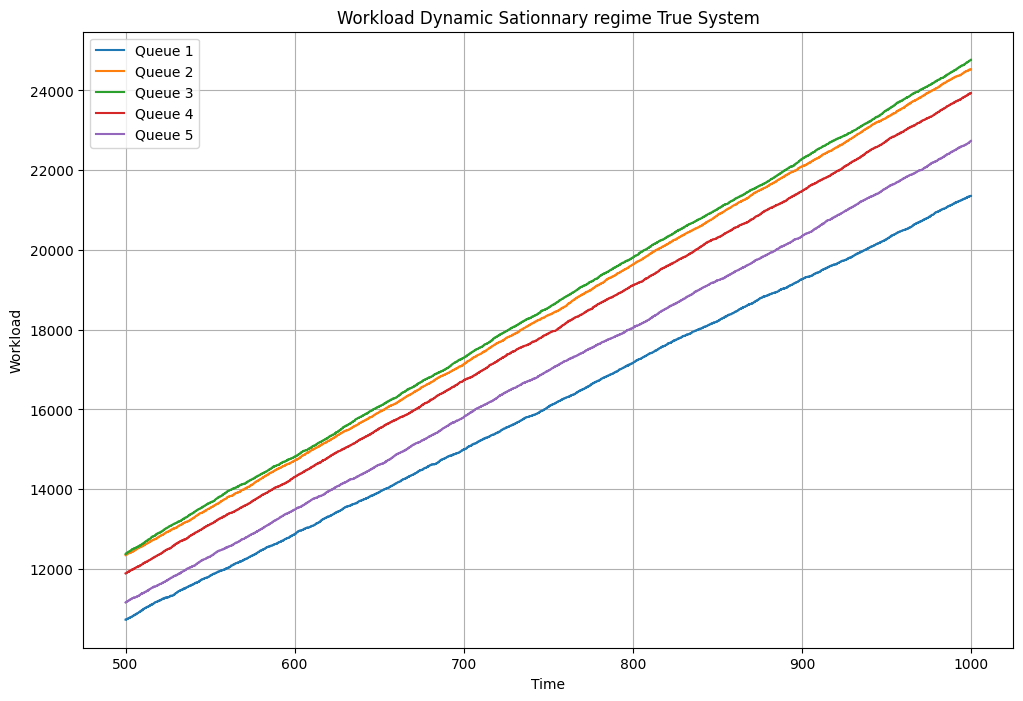

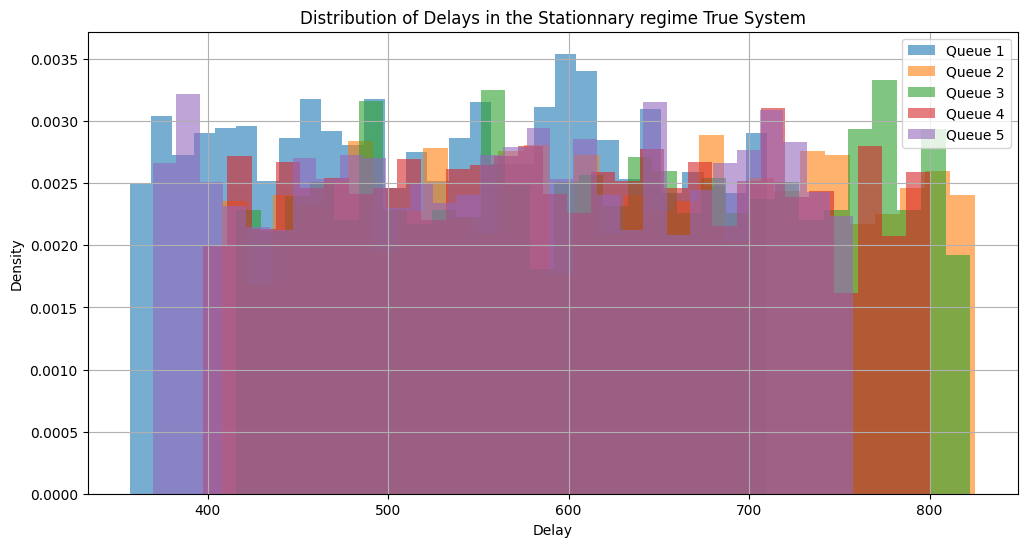

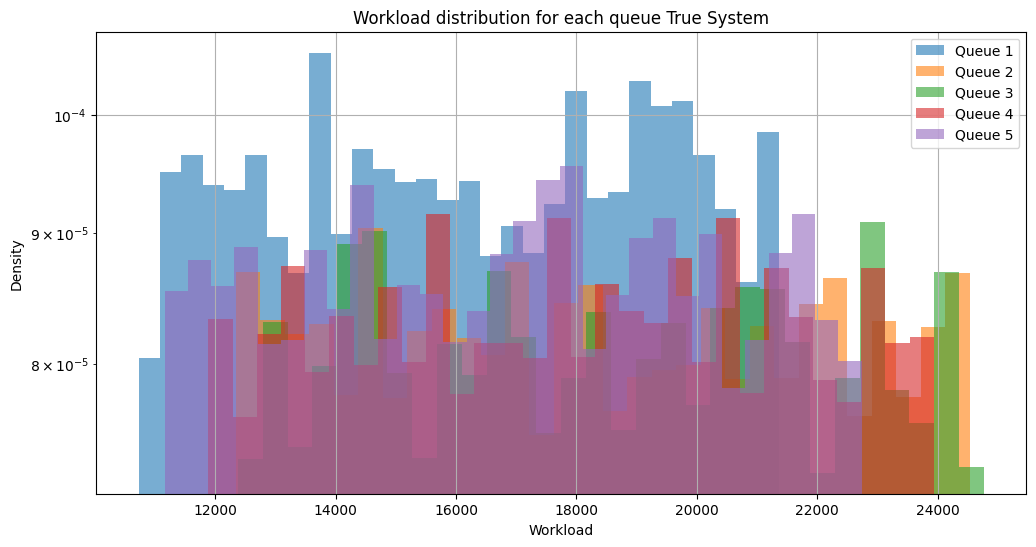

In [32]:
# Test 

f_p=find_fixed_point(
    15,
    psi,
    torus_size,
    f,
    g,
    x0=None,
    tolerance=1e-10,
    max_iterations=10000,
    relaxation=1.0)[0]
times2, all_workloads2, all_delays2 =simulate_multiple_mm1_queues(len(psi), 30, mu_tilde(f_p ,psi,g,f), T_max)

plot_workloads1(times2, all_workloads2, T_max, T)

plot_delays1(all_delays2,0.5)

plot_workload_distribution1(times2, all_workloads2, T_max, T)


## Simulate Mean-field 2

In [33]:
def solve_system_MF2(
    psi,
    lam,
    f,
    g,
    tol=1e-8,
    max_iter=1000,
    relaxation=0.5,
    p0=None
):
    """
    Solve the MF2 fixed-point system using exact enumeration.

    Parameters
    ----------
    psi : array-like
        Queue/node positions.
    lam : float
        Arrival rate.
    f : callable
        Path-loss function.
    g : callable
        Rate function applied to an interference array.
    d : callable
        Distance function d(i, j, psi).
    """

    N = len(psi)

    if lam < 0:
        raise ValueError("lam must be non-negative.")

    if not 0 < relaxation <= 1:
        raise ValueError("relaxation must belong to (0, 1].")

    # Interaction matrix:
    # W[m, l] = f(distance between m and l)
    W = np.zeros((N, N), dtype=float)

    for m in range(N):
        for l in range(N):
            if l != m:
                W[m, l] = f(torus_distance(psi[m],psi[l],torus_size))
                

    # Initial condition
    if p0 is None:
        p = np.zeros(N, dtype=float)
    else:
        p = np.clip(np.asarray(p0, dtype=float), 0.0, 1.0)

        if p.shape != (N,):
            raise ValueError("p0 must have shape (N,).")

    # Generate the 2^(N-1) activity configurations only once
    number_configurations = 2 ** (N - 1)

    integers = np.arange(number_configurations, dtype=np.uint64)

    bits = (
        (integers[:, None] >> np.arange(N - 1, dtype=np.uint64)) & 1
    ).astype(float)

    # Precompute, for every m:
    # - the indices different from m;
    # - the service rate associated with every activity configuration.
    active_indices = []
    rates = []

    for m in range(N):

        indices = np.delete(np.arange(N), m)
        active_indices.append(indices)

        # Interference for all configurations simultaneously
        interference = bits @ W[m, indices]

        # v_m(k) for every configuration k
        rate_m = np.asarray(g(interference), dtype=float)

        if rate_m.shape != (number_configurations,):
            raise ValueError(
                "g must accept and return a NumPy array."
            )

        rates.append(rate_m)

    history = []

    for iteration in range(1, max_iter + 1):

        expected_rates = np.empty(N)

        for m in range(N):

            p_other = p[active_indices[m]]

            # Probability of every Bernoulli configuration
            probabilities = np.prod(
                np.where(bits == 1, p_other, 1.0 - p_other),
                axis=1
            )

            expected_rates[m] = probabilities @ rates[m]

        if np.any(expected_rates <= 0):
            raise ValueError("The expected service rate must be positive.")

        # Fixed-point map
        target = np.minimum(1.0, lam / expected_rates)

        # Relaxed iteration
        p_next = (
            (1.0 - relaxation) * p
            + relaxation * target
        )

        error = np.max(np.abs(p_next - p))
        history.append(error)

        p = p_next

        if error < tol:
            break

    # Compute the true fixed-point residual
    final_expected_rates = np.empty(N)

    for m in range(N):

        p_other = p[active_indices[m]]

        probabilities = np.prod(
            np.where(bits == 1, p_other, 1.0 - p_other),
            axis=1
        )

        final_expected_rates[m] = probabilities @ rates[m]

    fixed_point_image = np.minimum(
        1.0,
        lam / final_expected_rates
    )

    residual = np.max(np.abs(fixed_point_image - p))

    info = {
        "iterations": iteration,
        "converged": residual < tol,
        "iteration_error": history[-1],
        "residual": residual,
        "history": history
    }

    return p, info, final_expected_rates

In [34]:
def calculate_departure_rate2_5(p, i, N,f,g,psi):
    interference=0
    for j in range(N):
        T=np.random.binomial(n=1, p=p[j])
        if j != i and T!=0: # if the neighbour j is buisy it affects i 
            distance=torus_distance(psi[i],psi[j],torus_size)
            interference+=f(T*distance)
    return g(interference)


def simulate_dynamic_queues2_5(psi, lambda_, T_max,f,g,p):
    t = 0
    N=len(psi)
    workloads = [0] * N # list that contain the workloads  of each queue
    arrival_times_list = [[] for _ in range(N)] # list that contain the list of arrival time of each job in each queue 
    delays_list = [[] for _ in range(N)] # list that contain the list of delays  of each job in each queue
    times = [0]  # keep track of any time where the system changes
    all_workloads = [[0] for _ in range(N)] # keep in memory the state of workloads at each time the system changes
    while t < T_max:
        arrival_times = [np.random.exponential(1 / lambda_) for _ in range(N)] # Generate potential arrival time for each queue 
        departure_rates = [calculate_departure_rate2_5(p, i, N,f,g,psi) for i in range(N)] 
        departure_times = [
            np.random.exponential(1 / rate) if rate > 0 and workloads[i] > 0 else float('inf')
            for i, rate in enumerate(departure_rates)
        ] # Generate potential departure time for each queue based on the wrokloads, workloads[i] > 0 check whether the queue is empty so that we can really pull out a job
        next_event_time = min(min(arrival_times), min(departure_times))# next event is the minimum between all those times 
        t += next_event_time
        if min(arrival_times) <= min(departure_times):# if it's an arrival that won the race
            queue_index = arrival_times.index(min(arrival_times)) # get the index of the queue who won
            workloads[queue_index] += 1 # add a job to the queue that won 
            arrival_times_list[queue_index].append(t)# we add the time at  which th job arrived in the queue that won 
        else:# if its a departure that won
            queue_index = departure_times.index(min(departure_times))# get the index 
            workloads[queue_index] -= 1 # pull of a job
            if arrival_times_list[queue_index]: # if the queue that won has jobs waiting 
                arrival_time = arrival_times_list[queue_index].pop(0) # we pop the first element of the waitng list( because it is the on being treated)
                delays_list[queue_index].append(t - arrival_time) # compute the time it tooked to be treated
        times.append(t) 
        for i in range(N):
            all_workloads[i].append(workloads[i])
    return times, all_workloads, delays_list

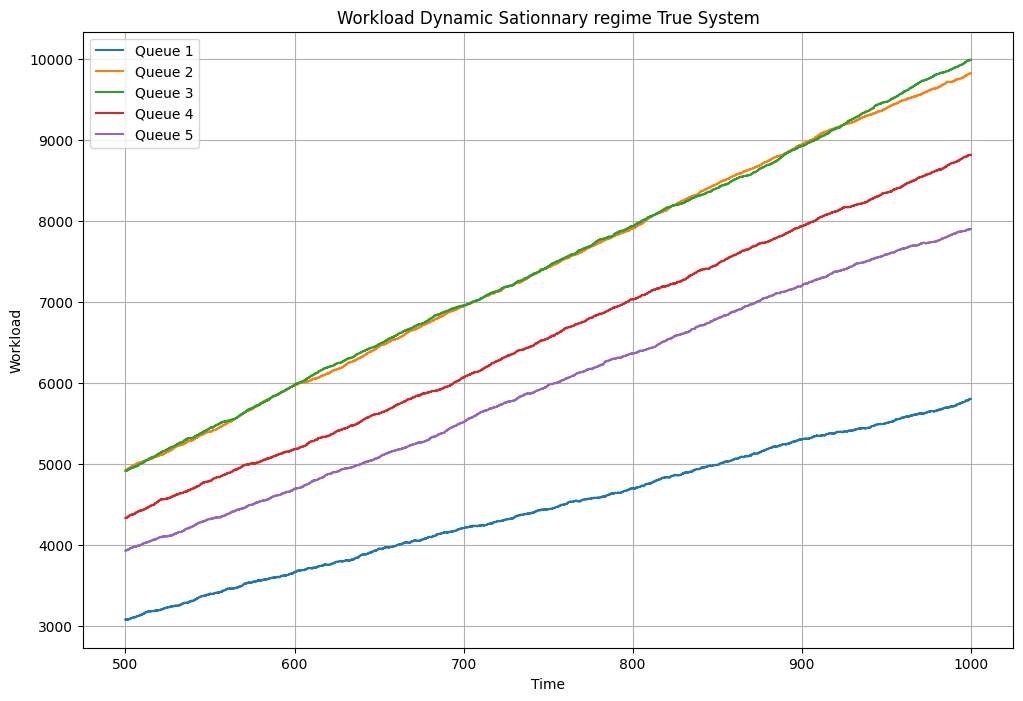

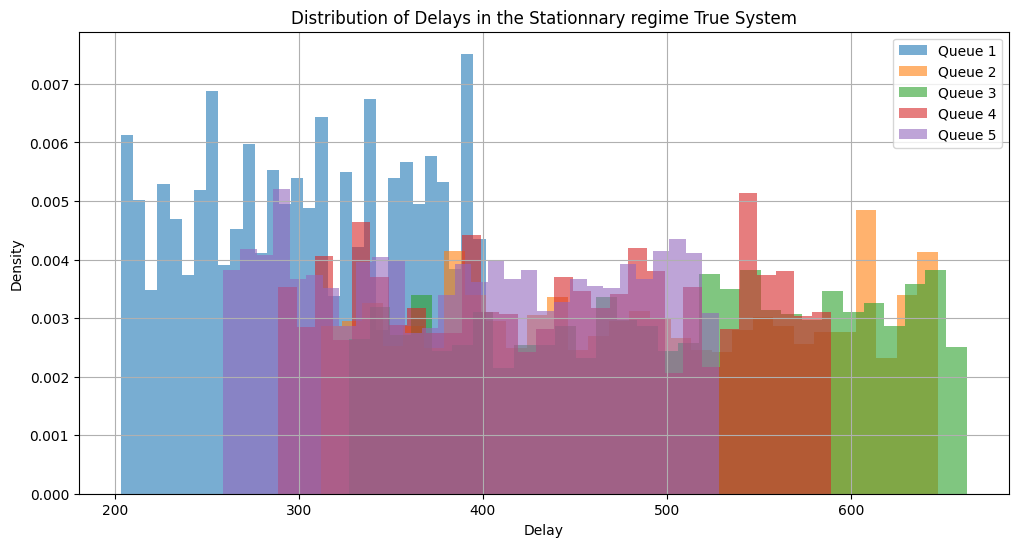

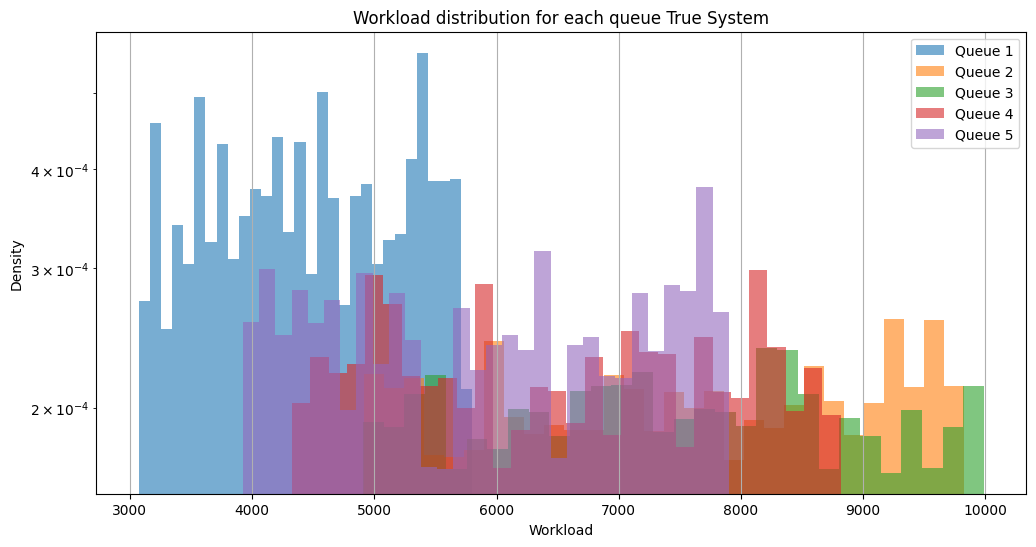

In [35]:
# Test 
p_star, info,L=solve_system_MF2(
    psi,
    15,
    f,
    g,
    tol=1e-8,
    max_iter=1000,
    relaxation=0.5,
    p0=None)
times2_5, all_workloads2_5, all_delays2_5 = simulate_dynamic_queues2_5(psi, 15, T_max,f,g,p_star)

plot_workloads1(times2_5, all_workloads2_5, T_max, T)

plot_delays1(all_delays2_5,0.5)

plot_workload_distribution1(times2_5,all_workloads2_5,T_max,T)

## Simulate AVG Mean-field 2

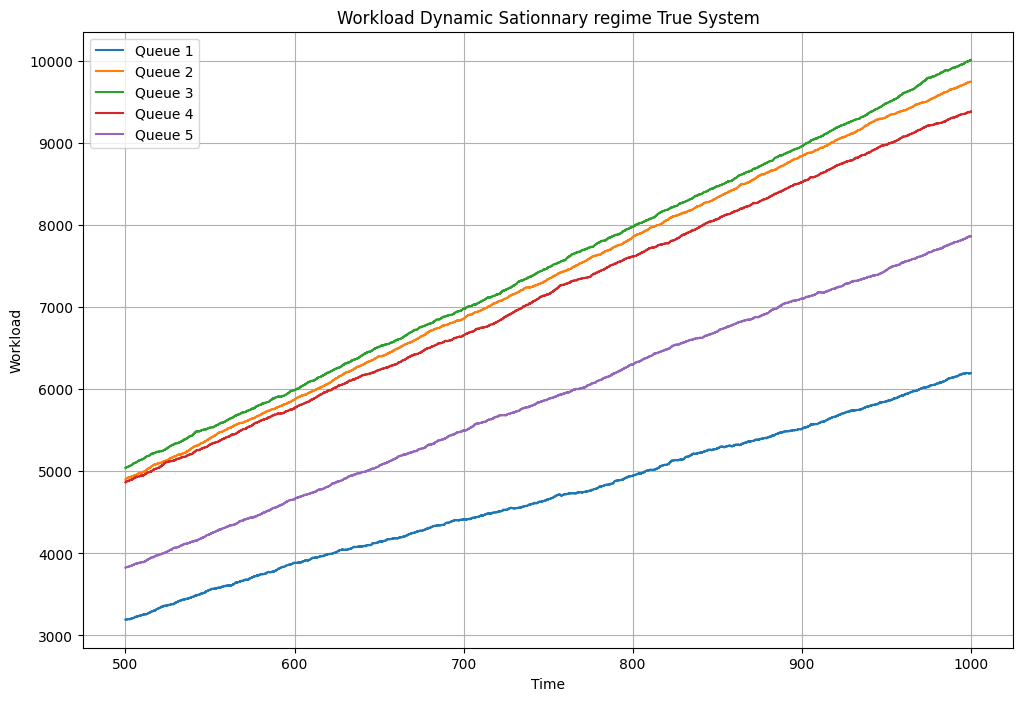

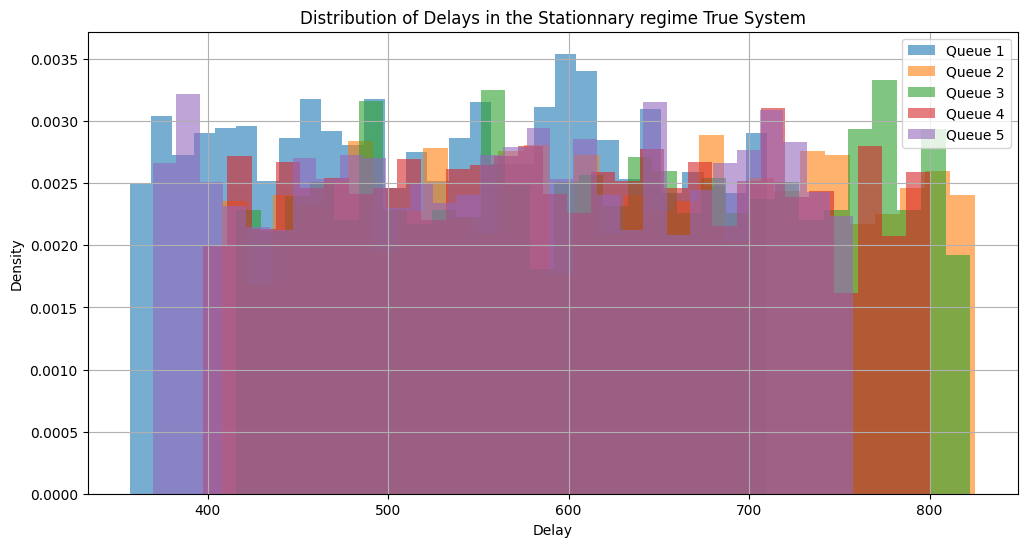

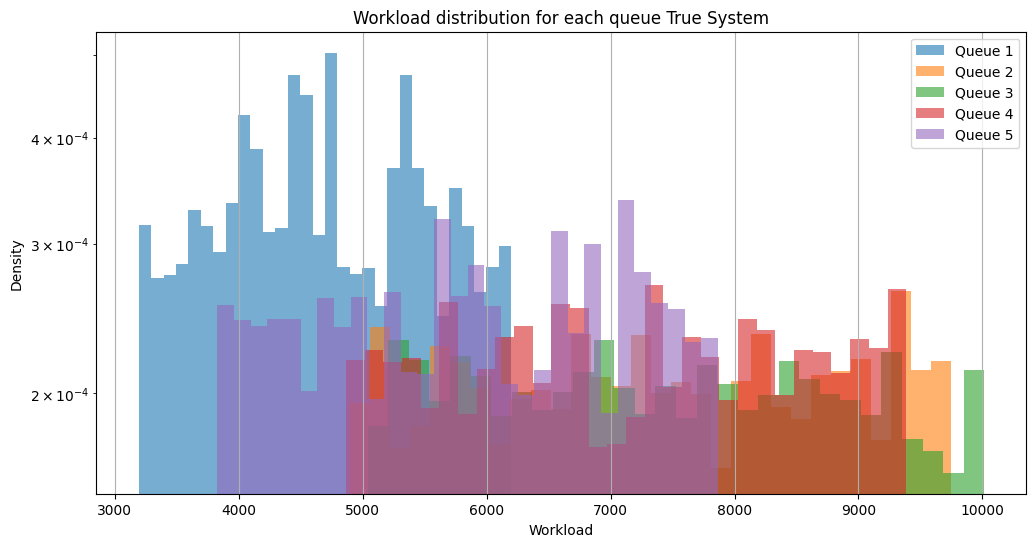

In [ ]:
# Test

p_star, info,L=solve_system_MF2(
    psi,
    15,
    f,
    g,
    tol=1e-8,
    max_iter=1000,
    relaxation=0.5,
    p0=None)

timesa2, all_workloadsa2, all_delaysa2 =simulate_multiple_mm1_queues(len(psi), 15,L, T_max)

plot_workloads1(timesa2, all_workloadsa2, T_max, T)

plot_delays1(all_delaysa2,0.5)

plot_workload_distribution1(timesa2, all_workloadsa2, T_max, T)

## Comparison of the systems

In [ ]:
# Here are the functions that allows us to access the true statistics and not the Palm one. Palm statistics being the ones seen from an arrival or departure point. 

def average_queue_length(times, workloads, T_max):
    area = 0.0
    for i in range(1, len(times)):
        dt = times[i] - times[i-1]
        area += workloads[i-1] * dt
    return area / T_max

def variance_queue_length(times, workloads, T_max):
    # Moyenne
    area = 0.0
    area_sq = 0.0
    for i in range(1, len(times)):
        dt = times[i] - times[i-1]
        area += workloads[i-1] * dt
        area_sq += (workloads[i-1]**2) * dt

    mean = area / T_max
    mean_sq = area_sq / T_max
    return mean_sq - mean**2

def count_non_zero(L):
    incr=0
    for i in L:
        if i!=0:
            incr+=1
    return incr

def occupation_queue(times, workloads, T_max):
    occupied_time = 0.0

    for i in range(1, len(times)):
        dt = times[i] - times[i - 1]
        occupied_time += (workloads[i - 1] > 0) * dt

    return occupied_time / T_max

In [ ]:
def compare_all_systems(g, f, psi, T, T_max, s, l, max_attempts):
    N=len(psi)
    lambda_values = np.linspace(0.1, 150, 100)

    # List for MF1
    
    mean_delays_rel_MF1, mean_workloads_rel_MF1 = [], []
    mean_delays_MF1, var_delays_MF1 = [], []
    mean_workloads_MF1_palm=[]
    mean_workloads_MF1, var_workloads_MF1 = [], []
    occup_MF1 = []
    occup_MF1_palm=[]

    # List for MF2
    
    mean_delays_rel_MF2_5, mean_workloads_rel_MF2_5 = [], []
    mean_delays_MF2_5, var_delays_MF2_5 = [], []
    mean_workloads_MF2_palm=[]
    mean_workloads_MF2_5, var_workloads_MF2_5 = [], []
    occup_MF2_5 = []
    occup_MF2_palm=[]

    # Listes pour avgMF2_5
   
    mean_delays_rel_avgMF2_5, mean_workloads_rel_avgMF2_5 = [], []
    mean_delays_avgMF2_5, var_delays_avgMF2_5 = [], []
    mean_workloads_aMF2_palm=[]
    mean_workloads_avgMF2_5, var_workloads_avgMF2_5 = [], []
    occup_avgMF2_5 = []
    occup_avgMF2_palm = []

    # List for the true system
    mean_delays_true, var_delays_true = [], []
    mean_workloads_palm=[]
    mean_workloads_true, var_workloads_true = [], []
    occup_true = []
    occup_true_palm = []

    #List FB
    
    mean_delays_rel_FB, mean_workloads_rel_FB = [], []
    mean_delays_FB, var_delays_FB = [], []
    mean_workloads_FB_palm=[]
    mean_workloads_FB, var_workloads_FB = [], []
    occup_FB = []
    occup_FB_palm=[]

    
    for lam in tqdm(lambda_values, total=len(lambda_values), desc="Comparaison des systèmes (lambda)", leave=True):

        # ===================== TRUE SYSTEM =====================
        times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi, lam, T_max, f, g)

        d1 = all_delays1[l][int(len(all_delays1[l]) * s):]
        

        filtered_times1 = [time for time in times1 if time >= T_max - T]
        start_index1 = len(times1) - len(filtered_times1)
        w1 = np.array(all_workloads1[l][start_index1:])
        m1 = average_queue_length(times1[start_index1:], w1, T)
        m1_palm=np.mean(w1)
        v1 = variance_queue_length(times1[start_index1:], w1, T)
        

        mean_delays_true.append(np.mean(d1))
        var_delays_true.append(np.var(d1))
        mean_workloads_true.append(m1)
        mean_workloads_palm.append(m1_palm)
        var_workloads_true.append(v1)
        occup_true_palm.append(count_non_zero(w1) / len(all_workloads1[l][start_index1:]))
        occup_true.append(occupation_queue(filtered_times1, w1, T))

        # ===================== MF1 =====================
        f_p=find_fixed_point(
        lam,
        psi,
        torus_size,
        f,
        g,
        x0=None,
        tolerance=1e-10,
        max_iterations=10000,
        relaxation=1.0)[0]
        mu_mf1 = mu_tilde(f_p ,psi,g,f)
        times_mf1, all_workloads_mf1, all_delays_mf1 = simulate_multiple_mm1_queues(N, lam, mu_mf1, T_max)

        d_mf1 = all_delays_mf1[l][int(len(all_delays_mf1[l]) * s):]
        

        filtered_times_mf1 = [time for time in times_mf1 if time >= T_max - T]
        start_index_mf1 = len(times_mf1) - len(filtered_times_mf1)
        w_mf1 = np.array(all_workloads_mf1[l][start_index_mf1:])
        m_mf1 = average_queue_length(times_mf1[start_index_mf1:], w_mf1, T)
        m_mf1_palm=np.mean(w_mf1)
        v_mf1 = variance_queue_length(times_mf1[start_index_mf1:], w_mf1, T)
        

        occup_MF1_palm.append(count_non_zero(w_mf1) / len(all_workloads_mf1[l][start_index_mf1:]))
        occup_MF1.append(occupation_queue(filtered_times_mf1, w_mf1, T))
        mean_delays_rel_MF1.append(np.abs(np.mean(d1) - np.mean(d_mf1)) / np.mean(d1))
        mean_workloads_rel_MF1.append(np.abs(m1 - m_mf1) / m1)
        mean_delays_MF1.append(np.mean(d_mf1))
        var_delays_MF1.append(np.var(d_mf1))
        mean_workloads_MF1.append(m_mf1)
        mean_workloads_MF1_palm.append(m_mf1_palm)
        var_workloads_MF1.append(v_mf1)

        # ===================== MF2 =====================
        p_star, info,L=solve_system_MF2(
        psi,
        lam,
        f,
        g,
        tol=1e-8,
        max_iter=1000,
        relaxation=0.5,
        p0=None)
        times_mf2, all_workloads_mf2, all_delays_mf2 = simulate_dynamic_queues2_5(psi, lam, T_max, f, g, p_star)

        d_mf2 = all_delays_mf2[l][int(len(all_delays_mf2[l]) * s):]
        

        filtered_times_mf2 = [time for time in times_mf2 if time >= T_max - T]
        start_index_mf2 = len(times_mf2) - len(filtered_times_mf2)
        w_mf2 = np.array(all_workloads_mf2[l][start_index_mf2:])
        m_mf2 = average_queue_length(times_mf2[start_index_mf2:], w_mf2, T)
        m_mf2_palm=np.mean(w_mf2)
        v_mf2 = variance_queue_length(times_mf2[start_index_mf2:], w_mf2, T)
        

        occup_MF2_palm.append(count_non_zero(w_mf2) / len(all_workloads_mf2[l][start_index_mf2:]))
        occup_MF2_5.append(occupation_queue(filtered_times_mf2, w_mf2, T))
        mean_delays_rel_MF2_5.append(np.abs(np.mean(d1) - np.mean(d_mf2)) / np.mean(d1))
        mean_workloads_rel_MF2_5.append(np.abs(m1 - m_mf2) / m1)
        mean_delays_MF2_5.append(np.mean(d_mf2))
        var_delays_MF2_5.append(np.var(d_mf2))
        mean_workloads_MF2_5.append(m_mf2)
        mean_workloads_MF2_palm.append(m_mf2_palm)
        var_workloads_MF2_5.append(v_mf2)

        # ===================== avgMF2 =====================
        
        times_avg, all_workloads_avg, all_delays_avg = simulate_multiple_mm1_queues(N, lam,L, T_max)

        d_avg = all_delays_avg[l][int(len(all_delays_avg[l]) * s):]
        

        filtered_times_avg = [time for time in times_avg if time >= T_max - T]
        start_index_avg = len(times_avg) - len(filtered_times_avg)
        w_avg = np.array(all_workloads_avg[l][start_index_avg:])
        m_avg = average_queue_length(times_avg[start_index_avg:], w_avg, T)
        m_avg_palm=np.mean(w_avg)
        v_avg = variance_queue_length(times_avg[start_index_avg:], w_avg, T)
        

        occup_avgMF2_palm.append(count_non_zero(w_avg) / len(all_workloads_avg[l][start_index_avg:]))
        occup_avgMF2_5.append(occupation_queue(filtered_times_avg, w_avg, T))
        mean_delays_rel_avgMF2_5.append(np.abs(np.mean(d1) - np.mean(d_avg)) / np.mean(d1))
        mean_workloads_rel_avgMF2_5.append(np.abs(m1 - m_avg) / m1)
        mean_delays_avgMF2_5.append(np.mean(d_avg))
        var_delays_avgMF2_5.append(np.var(d_avg))
        mean_workloads_avgMF2_5.append(m_avg)
        mean_workloads_aMF2_palm.append(m_avg_palm)
        var_workloads_avgMF2_5.append(v_avg)

        # ===================== FB =====================
        times_FB, all_workloads_FB, all_delays_FB = simulate_dynamic_queues2_5(psi,lam,T_max,f,g,np.ones(len(psi)))
    
        d_FB = all_delays_FB[l][int(len(all_delays_FB[l]) * s):]
        

        filtered_times_FB = [time for time in times_FB if time >= T_max - T]
        start_index_FB = len(times_FB) - len(filtered_times_FB)
        w_FB = np.array(all_workloads_FB[l][start_index_FB:])
        m_FB = average_queue_length(times_FB[start_index_FB:], w_FB, T)
        m_FB_palm=np.mean(w_FB)
        v_FB = variance_queue_length(times_FB[start_index_FB:], w_FB, T)
        

        
        occup_FB_palm.append(count_non_zero(w_FB) / len(all_workloads_FB[l][start_index_FB:]))
        occup_FB.append(occupation_queue(filtered_times_FB, w_FB, T))
        mean_delays_rel_FB.append(np.abs(np.mean(d1) - np.mean(d_FB)) / np.mean(d1))
        mean_workloads_rel_FB.append(np.abs(m1 - m_FB) / m1)
        mean_delays_FB.append(np.mean(d_FB))
        var_delays_FB.append(np.var(d_FB))
        mean_workloads_FB.append(m_FB)
        mean_workloads_FB_palm.append(m_FB_palm)
        var_workloads_FB.append(v_FB)


    return {
        'lambda_values': lambda_values,
        # True system
        'mean_delays_true': mean_delays_true, 'var_delays_true': var_delays_true,
        'mean_workloads_true': mean_workloads_true, 'var_workloads_true': var_workloads_true,
        'mean_workloads_true_palm': mean_workloads_palm,
        'occup_true': occup_true,
        'occup_true_palm':occup_true_palm,
        # MF1
        
        'mean_delays_rel_MF1': mean_delays_rel_MF1, 'mean_workloads_rel_MF1': mean_workloads_rel_MF1,
        'mean_delays_MF1': mean_delays_MF1, 'var_delays_MF1': var_delays_MF1,
        'mean_workloads_MF1': mean_workloads_MF1, 'var_workloads_MF1': var_workloads_MF1,
        'mean_workloads_MF1_palm':mean_workloads_MF1_palm,
        'occup_MF1': occup_MF1,
        'occup_MF1_palm': occup_MF1_palm,
        # MF2_5
        
        'mean_delays_rel_MF2_5': mean_delays_rel_MF2_5, 'mean_workloads_rel_MF2_5': mean_workloads_rel_MF2_5,
        'mean_delays_MF2_5': mean_delays_MF2_5, 'var_delays_MF2_5': var_delays_MF2_5,
        'mean_workloads_MF2_5': mean_workloads_MF2_5, 'var_workloads_MF2_5': var_workloads_MF2_5,
        'mean_workloads_MF2_palm':mean_workloads_MF2_palm,
        'occup_MF2_5': occup_MF2_5,
        'occup_MF2_palm': occup_MF2_palm,
        # avgMF2_5
        
        'mean_delays_rel_avgMF2_5': mean_delays_rel_avgMF2_5, 'mean_workloads_rel_avgMF2_5': mean_workloads_rel_avgMF2_5,
        'mean_delays_avgMF2_5': mean_delays_avgMF2_5, 'var_delays_avgMF2_5': var_delays_avgMF2_5,
        'mean_workloads_avgMF2_5': mean_workloads_avgMF2_5, 'var_workloads_avgMF2_5': var_workloads_avgMF2_5,
        'mean_workload_aMF2_palm':mean_workloads_aMF2_palm,
        'occup_avgMF2_5': occup_avgMF2_5,
        'occup_aMF2_palm':occup_avgMF2_palm,
        # FB
        
        'mean_delays_rel_FB': mean_delays_rel_FB, 'mean_workloads_rel_FB': mean_workloads_rel_FB,
        'mean_delays_FB': mean_delays_FB, 'var_delays_FB': var_delays_FB,
        'mean_workloads_FB': mean_workloads_FB, 'var_workloads_FB': var_workloads_FB,
        'mean_workload_FB_palm':mean_workloads_FB_palm,
        'occup_FB': occup_FB,
        'occup_FB_palm':occup_FB_palm

    }


In [39]:
def plot_comparison(res, save=False, prefix="figure"):

    lam = res['lambda_values']

    # Tailles plus grosses
    LEGEND_SIZE = 18
    LABEL_SIZE = 20
    TITLE_SIZE = 22
    TICK_SIZE = 16

    FIGSIZE = (10, 8)

    colors = {
        'true': 'black',
        'MF1': 'blue',
        'MF2_5': 'red',
        'avgMF2_5': 'green',
        'FB': 'purple'
    }

    styles = {
        'true': '-',
        'MF1': '--',
        'MF2_5': '-.',
        'avgMF2_5': ':',
        'FB': (0, (3, 1, 1, 1))
    }

    def finalize_plot(ax, ylabel, title, logy=False, legend_size=LEGEND_SIZE):
        if logy:
            ax.set_yscale('log')

        ax.set_xlabel('λ', fontsize=LABEL_SIZE)
        ax.set_ylabel(ylabel, fontsize=LABEL_SIZE)
        ax.set_title(title, fontsize=TITLE_SIZE, pad=15)
        ax.tick_params(axis='both', labelsize=TICK_SIZE)
        ax.legend(fontsize=legend_size)
        ax.grid(True, alpha=0.3)

    def plot5(true_data, mf1_data, mf2_data, avg_data, fb_data,
              ylabel, title, logy=False, filename=None):

        fig, ax = plt.subplots(figsize=FIGSIZE)

        if true_data is not None:
            ax.plot(
                lam,
                true_data,
                color=colors['true'],
                linestyle=styles['true'],
                label='True',
                linewidth=2.5
            )

        if mf1_data is not None:
            ax.plot(
                lam,
                mf1_data,
                color=colors['MF1'],
                linestyle=styles['MF1'],
                label='MF1',
                linewidth=2
            )

        if mf2_data is not None:
            ax.plot(
                lam,
                mf2_data,
                color=colors['MF2_5'],
                linestyle=styles['MF2_5'],
                label='MF2',
                linewidth=2
            )

        if avg_data is not None:
            ax.plot(
                lam,
                avg_data,
                color=colors['avgMF2_5'],
                linestyle=styles['avgMF2_5'],
                label='avg MF2',
                linewidth=2.5
            )

        if fb_data is not None:
            ax.plot(
                lam,
                fb_data,
                color=colors['FB'],
                linestyle=styles['FB'],
                label='FB',
                linewidth=2.5
            )

        finalize_plot(ax, ylabel, title, logy=logy)

        plt.tight_layout()

        if save and filename is not None:
            plt.savefig(filename, dpi=300, bbox_inches='tight')

        plt.show()

    def plot4_approx(mf1_data, mf2_data, avg_data, fb_data,
                     ylabel, title, hline=None, logy=False, filename=None):

        fig, ax = plt.subplots(figsize=FIGSIZE)

        ax.plot(
            lam,
            mf1_data,
            color=colors['MF1'],
            linestyle=styles['MF1'],
            label='MF1',
            linewidth=2
        )

        ax.plot(
            lam,
            mf2_data,
            color=colors['MF2_5'],
            linestyle=styles['MF2_5'],
            label='MF2',
            linewidth=2
        )

        ax.plot(
            lam,
            avg_data,
            color=colors['avgMF2_5'],
            linestyle=styles['avgMF2_5'],
            label='avg MF2',
            linewidth=2.5
        )

        ax.plot(
            lam,
            fb_data,
            color=colors['FB'],
            linestyle=styles['FB'],
            label='FB',
            linewidth=2.5
        )

        if hline is not None:
            ax.axhline(
                y=hline,
                color='gray',
                linestyle=':',
                alpha=0.5,
                label=f'y = {hline}'
            )

        finalize_plot(ax, ylabel, title, logy=logy)

        plt.tight_layout()

        if save and filename is not None:
            plt.savefig(filename, dpi=300, bbox_inches='tight')

        plt.show()

    
    # ============================================================
    # 1. Delays
    # ============================================================

    plot5(
        res['mean_delays_true'],
        res['mean_delays_MF1'],
        res['mean_delays_MF2_5'],
        res['mean_delays_avgMF2_5'],
        res['mean_delays_FB'],
        'E[D]',
        'Mean Delay (log)',
        logy=True,
        filename=f"{prefix}_mean_delay.pdf"
    )

    plot4_approx(
        res['mean_delays_rel_MF1'],
        res['mean_delays_rel_MF2_5'],
        res['mean_delays_rel_avgMF2_5'],
        res['mean_delays_rel_FB'],
        'Relative Error',
        'Relative Error - Mean Delay (log)',
        logy=True,
        filename=f"{prefix}_rel_error_mean_delay.pdf"
    )

    plot5(
        res['var_delays_true'],
        res['var_delays_MF1'],
        res['var_delays_MF2_5'],
        res['var_delays_avgMF2_5'],
        res['var_delays_FB'],
        'Var[D]',
        'Delay Variance (log)',
        logy=True,
        filename=f"{prefix}_var_delay.pdf"
    )

    # ============================================================
    # 2. Workloads
    # ============================================================

    plot5(
        res['mean_workloads_true'],
        res['mean_workloads_MF1'],
        res['mean_workloads_MF2_5'],
        res['mean_workloads_avgMF2_5'],
        res['mean_workloads_FB'],
        'E[W]',
        'Mean Workload (log)',
        logy=True,
        filename=f"{prefix}_mean_workload.pdf"
    )

    plot4_approx(
        res['mean_workloads_rel_MF1'],
        res['mean_workloads_rel_MF2_5'],
        res['mean_workloads_rel_avgMF2_5'],
        res['mean_workloads_rel_FB'],
        'Relative Error',
        'Relative Error - Mean Congestion (log)',
        logy=True,
        filename=f"{prefix}_rel_error_mean_workload.pdf"
    )

    plot5(
        res['var_workloads_true'],
        res['var_workloads_MF1'],
        res['var_workloads_MF2_5'],
        res['var_workloads_avgMF2_5'],
        res['var_workloads_FB'],
        'Var[W]',
        'Workload Variance (log)',
        logy=True,
        filename=f"{prefix}_var_workload.pdf"
    )

    plot5(
            res['mean_workloads_true_palm'],
            res['mean_workloads_MF1_palm'],
            res['mean_workloads_MF2_palm'],
            res['mean_workload_aMF2_palm'],
            res['mean_workload_FB_palm'],
            'E^0[W]',
            'Palm Mean Workload (log)',
            logy=True,
            filename=f"{prefix}_mean_workload.pdf"
        )




    # ============================================================
    # 4. Occupation
    # ============================================================

    plot5(
        res['occup_true'],
        res['occup_MF1'],
        res['occup_MF2_5'],
        res['occup_avgMF2_5'],
        res['occup_FB'],
        'P[W > 0]',
        'Server Occupation Probability',
        filename=f"{prefix}_occupation_probability.pdf"
    )
    plot5(
            res['occup_true_palm'],
            res['occup_MF1_palm'],
            res['occup_MF2_palm'],
            res['occup_aMF2_palm'],
            res['occup_FB_palm'],
            'P^0[W > 0]',
            'Server Occupation Palm Probability',
            filename=f"{prefix}_occupation_probability.pdf"
        )


    

In [ ]:
# Test , Can be long since we monte carlo simulate the true system for different value of lambda
T_max=10**3
T=10**2
res = compare_all_systems(g, f, psi, T, T_max, 0.5, 4, 10)
plot_comparison(res)

Comparaison des systèmes (lambda):  31%|███       | 31/100 [2:12:13<3:54:59, 204.33s/it]  

## Counter Example 1

In [ ]:

def calcule_mu_star2(psi,f,g,l): # For fix l, determine the service rate where everyone is busy excpt the i-th queue. Return the list of this service rate when i varies
    N=len(psi)
    res=[]
    for i in range(len(psi)):
        interference=0
        for j in range(len(psi)):
            if j!=i:
                distance= torus_distance(psi[l],psi[j],torus_size)
                if distance > 0:
                    interference+=f(distance)
        res.append(g(interference))
    return res

def best_couple(psi,i,f,g): # Exploit the quantity of Theoreml 4.1. It consists in finding the best other queue to extract with queue i to realize the stochastic bound. 
    res=[]
    c1=calcule_mu_star2(psi,f,g,i)
    c2=calcule_mu_star(psi,f,g)
    for j in range(len(psi)):
        res.append(c2[j]*c1[j]/(c2[j]-c2[i]+c1[j]))
    return np.max(res),np.argmax(res)


def deux_plus_petits_indices(liste): # Technical function that gets indices of two most little elements in a list
    if len(liste) < 2:
        raise ValueError("La liste doit contenir au moins deux éléments")

    # On récupère les indices des deux plus petits éléments
    indices_tries = sorted(range(len(liste)), key=lambda i: liste[i])
    return indices_tries[0], indices_tries[1]





def two_worst_mu_star(psi,f,g): # This function gets the the indices of the two worst queue in term of worst servcie rate, in order to exhbit a counter example in the order of explosion for this queues.
    return deux_plus_petits_indices(calcule_mu_star(psi,f,g))



def lower_bound(psi,l,f,g): # We compute here the quantity C in the stochastic bounds part. It consists to find what is the best queue you can exctract with queue l to relaize the bound
    res=[]
    N=len(psi)
    for j in range(len(psi)):
        if j!=l:
             distance = torus_distance(psi[l],psi[j],torus_size)
             if distance > 0:
                res.append(g(f(distance)))
    return np.min(res)



def try_to_find_counter_example(N,attempt,prec,f,g,Seed=None): # Find a counter example where the second worst \mu^* blow before the worst one. 
    if Seed is not None:
        random.seed(Seed)
    points = [random.uniform(0, N-1) for _ in range(N)] 
    i,j=deux_plus_petits_indices(calcule_mu_star(points,f,g))
    c=0
    # Une tentative = un point aléatoire testé; total connu, donc ETA exploitable.
    # leave=False évite de conserver une barre temporaire dans une fonction appelée ailleurs.
    with tqdm(total=attempt, desc="Recherche de contre-exemple", leave=False) as pbar:
        while(not(best_couple(points,i,f,g)[0]-lower_bound(points,j,f,g)>prec) and c<attempt):
            points = [random.uniform(0, N-1) for _ in range(N)] 
            i,j=deux_plus_petits_indices(calcule_mu_star(points,f,g))
            c+=1
            pbar.update(1)
    
    if c==attempt:
        return [],0,c
    else:
        return points,best_couple(points,i,f,g)[0],lower_bound(points,j,f,g),c



In [ ]:
# Test
f,g=OPL(1,3,0,1),Shanon_rate(100,1,1)
T_max=10**5
T=5*10**4
psi_c,U,L,c=try_to_find_counter_example(6,10**5,5*10**(-6),f,g,Seed=42)
i,j=two_worst_mu_star(psi_c,f,g)

plot_points_reels(psi_c),U,L,psi_c,i,j

In [ ]:


times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi_c, 2.6, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)

plot_delays1(all_delays1,0.5)

plot_workload_distribution1(times1,all_workloads1,T_max,T)

## Counter Example 2

In [ ]:
psi=[0.8943685832887711,
 1.4773267760536166,
 1.6302020272007924,
 2.82085718774153,
 2.8737262952394014]


In [ ]:
def calcule_mu_sature_1(psi,l,f,g):# List of the Service rate where evryone is busy except the l-th queue
    res=[]
    N=len(psi)
    for i in range(N):
        interference=0
        for j in range(N):
            if j !=l:
                distance = torus_distance(psi[i],psi[j],torus_size)
                if distance > 0:
                    interference+=f(distance)
        res.append(g(interference))
    return res



def mean_service_rate_1(psi,f,g,lambda_,k):# Average service rate under the stationnary distribution of the first stable queue
    M=calcule_mu_star(psi,f,g)
    first=np.argmax(M)
    if k==first:
        return 0
    elif lambda_>M[first]:
        return 0
    else:
        mu_star_first=M[first]
        mu_star_k=M[k]
        mu_sature_k_1=calcule_mu_sature_1(psi,first,f,g)[k]
        return (lambda_/ mu_star_first)*mu_star_k+(1-(lambda_/mu_star_first))*mu_sature_k_1


In [ ]:
# Here we plot the graphical solution of the equation

# 1) mu* and bounds
mu_vals = calcule_mu_star(psi, f, g)
lambda_max = max(mu_vals)

# Domain over which the functions are plotted (as initially intended)
lambda_min = lambda_max              # Adjust as needed
# lambda_min = 0.2 * lambda_max  # Alternative option

# Display window extended to the right
lambda_plot_max = 5
lambda_plot_min = 0  # Must be > lambda_max

print("mu* =", mu_vals)
print("Domaine fonctions   :", lambda_min, "→", lambda_max)
print("Fenêtre affichage   :", lambda_min, "→", lambda_plot_max)

# 2) Grid for the functions (identity + mean_service_rate)
Y = np.linspace(0, lambda_plot_max, 10000)
Y_1=np.linspace(0, lambda_max, 10000)

colors = plt.cm.tab20(np.linspace(0, 1, len(psi)))
plt.figure(figsize=(10, 6))

all_rates = []

# 3) mean_service_rate curves (over [lambda_min, lambda_max])
for i in range(len(psi)):
    color = colors[i]

    X_i = [mean_service_rate_1(psi, f, g, lam, i) for lam in Y]
    all_rates.append(X_i)

    plt.plot(
        Y, X_i,
        color=color,
        linewidth=1.5,
        label=f"Queue {i+1}"
    )

# 4) Identity line over the same domain [lambda_min, lambda_max]
plt.plot(Y, Y, 'k--', linewidth=2)#label="Identity y = x")

# 5) mu* horizontal lines only over the extended interval [lambda_max, lambda_plot_max]
for i in range(len(psi)):
    color = colors[i]
    plt.hlines(
        mu_vals[i],
        xmin=lambda_max,
        xmax=lambda_plot_max,
        colors=[color],
        linestyles="dashed",
        linewidth=1.5,
        label="_nolegend_"
    )

# 6) Axes
y_max_curves = max(max(r) for r in all_rates)
y_max = max(y_max_curves, max(mu_vals))
plt.xlim(lambda_plot_min, lambda_plot_max)
plt.ylim(0.5, 0.525)

plt.xlabel(r"$\lambda$")
plt.ylabel("Taux de service")
#plt.title()
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Stability Region Heuristic

In [ ]:
# Check the number of ones in the fixed-point solution

def has_exactly_n_ones(lst, n):
    """
    Check whether `lst` contains exactly `n` occurrences of the value 1.

    :param lst: iterable of values
    :param n: expected number of occurrences of 1
    :return: True if lst contains exactly n ones, False otherwise
    """
    return np.sum(lst==1)==n

# Return the thresholds and the queues that become unstable first

def lambdas_crit2(psi,f,g):
    lambdas = []
    indices_list = []  # Store the list of indices at each step
    lambda_ = 0.005

    # Track progress over the requested values of n; the inner loop increments lambda
    # in steps and calls a solver without progress reporting, so no reliable inner progress bar is available.
    for n in tqdm(range(len(psi)), total=len(psi), desc="Recherche des seuils lambda", leave=True):
        # Search for the lambda at which the number of components equal to 1 changes from n
        while has_exactly_n_ones(find_fixed_point(lambda_, psi,torus_size,f,g,x0=None,
            tolerance=1e-9,
            max_iterations=100,
            relaxation=1.0)[0], n):
            lambda_ += 0.001

        # Once found, store lambda and the corresponding indices
        sol = find_fixed_point(lambda_, psi,torus_size,f,g,x0=None,
            tolerance=1e-9,
            max_iterations=100,
            relaxation=1.0)[0]
        lambdas.append(lambda_)
        indices_list.append([i for i, val in enumerate(sol) if val == 1])

    return lambdas, indices_list

In [ ]:
lambdas_crit2(psi_c,f,g)

# Here we visually test the algorithm

In [ ]:
times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi_c, 2.5, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)

In [ ]:
times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi_c, 3.3, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)

In [ ]:
times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi_c, 4.1, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)

In [ ]:
times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi_c, 5.3, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)

In [ ]:
times1, all_workloads1, all_delays1 = simulate_dynamic_queues(psi_c, 8, T_max,f,g)

plot_workloads1(times1, all_workloads1, T_max, T)